# 02 EDA and RFM segmentation

CartPadi Nigeria Ltd. is a fictional marketplace and every row here is synthetic (see notebook 01 and `scripts/01_data_generation.py`).

This notebook has two parts.

Part A audits and explores the raw data: quality checks, revenue, order behaviour, products, geography, payment and acquisition.

Part B scores every customer on recency, frequency and monetary value (RFM) and puts them into eight segments.

Output: `data/processed/rfm_segments.csv`

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cartpadi as cp

cp.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 20)

raw = cp.load_raw()
{name: df.shape for name, df in raw.items()}

{'customers': (25000, 9),
 'orders': (121208, 9),
 'order_items': (275582, 6),
 'products': (2000, 6),
 'sessions': (480000, 8)}

## Part A: exploratory analysis

### A1. Data quality audit

Six checks before any analysis: types, nulls, duplicates, date ranges, keys between tables, and whether order totals reconcile to their line items.

In [2]:
for name, df in raw.items():
    print(f"{name}: {len(df):,} rows")
    print(df.dtypes.to_string(), end="\n\n")

customers: 25,000 rows
customer_id                       str
signup_date            datetime64[us]
state                             str
city                              str
age_group                         str
gender                            str
acquisition_channel               str
first_device                      str
is_churned                      int64

orders: 121,208 rows
order_id                      str
customer_id                   str
order_date         datetime64[us]
order_status                  str
payment_method                str
order_total_ngn           float64
discount_ngn              float64
delivery_days             float64
delivery_state                str

order_items: 275,582 rows
item_id               str
order_id              str
product_id            str
quantity            int64
unit_price_ngn    float64
discount_pct      float64

products: 2,000 rows
product_id            str
product_name          str
category              str
subcategory           st

In [3]:
nulls = pd.concat({name: df.isna().sum() for name, df in raw.items()}).rename("nulls")
nulls[nulls > 0].to_frame().assign(share=lambda d: d["nulls"] / [len(raw[t]) for t, _ in d.index])

,,nulls,share
customers,city,221,0.01
orders,delivery_days,6853,0.06
sessions,customer_id,147984,0.31


Three columns have gaps. Two are by design: `delivery_days` is empty for cancelled orders (nothing shipped), and `customer_id` is empty for anonymous site visitors. The third is a real gap: some customers have no city on record. City is not used in any model, so these get "Unknown".

In [4]:
orders = raw["orders"]
dup_rows = orders.duplicated().sum()
dup_ids = orders["order_id"].duplicated().sum()
print(f"Exact duplicate order rows: {dup_rows}")
print(f"Duplicate order_ids:        {dup_ids}")
orders[orders["order_id"].duplicated(keep=False)].sort_values("order_id").head(6)

Exact duplicate order rows: 182
Duplicate order_ids:        182


,order_id,customer_id,order_date,order_status,payment_method,order_total_ngn,discount_ngn,delivery_days,delivery_state
871,CP-0000872,2c745999-0671-4ef6-bed3-d46765f4e39f,2024-02-02 07:24:34,delivered,card,"8,750.00",0.00,3.00,Lagos
872,CP-0000872,2c745999-0671-4ef6-bed3-d46765f4e39f,2024-02-02 07:24:34,delivered,card,"8,750.00",0.00,3.00,Lagos
1112,CP-0001112,748829a5-0027-4cb8-a236-7df34c6c00dc,2024-02-08 11:12:35,delivered,card,"20,950.00",0.00,7.00,Rivers
1113,CP-0001112,748829a5-0027-4cb8-a236-7df34c6c00dc,2024-02-08 11:12:35,delivered,card,"20,950.00",0.00,7.00,Rivers
1918,CP-0001917,36af5ae6-9d50-4b49-b980-ca013f02f2a3,2024-02-29 16:09:16,delivered,CartPadi_wallet,"15,500.00",0.00,3.00,Lagos
1919,CP-0001917,36af5ae6-9d50-4b49-b980-ca013f02f2a3,2024-02-29 16:09:16,delivered,CartPadi_wallet,"15,500.00",0.00,3.00,Lagos


Every repeated `order_id` is an exact copy of another row, so this is a double export, not two real orders sharing an ID. Keeping them would overstate GMV, so they are dropped.

In [5]:
t = cp.clean(raw)
customers, orders, items, products, sessions = (t[k] for k in
    ["customers", "orders", "order_items", "products", "sessions"])

checks = {
    "order dates": (orders["order_date"].min(), orders["order_date"].max()),
    "signup dates": (customers["signup_date"].min(), customers["signup_date"].max()),
    "session dates": (sessions["session_date"].min(), sessions["session_date"].max()),
}
for k, (lo, hi) in checks.items():
    print(f"{k:<14} {lo}  to  {hi}")

signup = orders.merge(customers[["customer_id", "signup_date"]], on="customer_id")
print("\nOrders placed before signup:", (signup["order_date"].dt.normalize() < signup["signup_date"]).sum())
print("Orders with unknown customer:", (~orders["customer_id"].isin(customers["customer_id"])).sum())
print("Lines with unknown order:    ", (~items["order_id"].isin(orders["order_id"])).sum())
print("Lines with unknown product:  ", (~items["product_id"].isin(products["product_id"])).sum())
print("Sessions with unknown customer:", (~sessions["customer_id"].dropna().isin(customers["customer_id"])).sum())

line_net = (items["quantity"] * items["unit_price_ngn"] * (1 - items["discount_pct"] / 100)).groupby(items["order_id"]).sum()
gap = (orders.set_index("order_id")["order_total_ngn"] - line_net).abs()
print("Orders whose total is off its lines by more than N1:", (gap > 1).sum())
print("Negative totals, prices or quantities:",
      int((orders["order_total_ngn"] < 0).sum() + (items["unit_price_ngn"] <= 0).sum() + (items["quantity"] <= 0).sum()))

order dates    2024-01-01 07:11:53  to  2025-12-31 23:59:40
signup dates   2024-01-01 00:00:00  to  2025-12-31 00:00:00
session dates  2024-01-01 00:44:39  to  2025-12-31 23:59:54

Orders placed before signup: 0
Orders with unknown customer: 0
Lines with unknown order:     0
Lines with unknown product:   0
Sessions with unknown customer: 0


Orders whose total is off its lines by more than N1: 0
Negative totals, prices or quantities: 0


The data is clean apart from the duplicates and missing cities. All dates sit inside January 2024 to December 2025, every key resolves, and every order total matches its line items.

One definition for the rest of the project: GMV is the value of all orders that were not cancelled. Returned orders count in GMV but not in net revenue.

In [6]:
orders["month"] = orders["order_date"].dt.to_period("M")
live = orders[orders["order_status"] != "cancelled"].copy()
lead_cat = cp.first_order_category(items, products)

aov = live.assign(cat=live["order_id"].map(lead_cat))

pd.Series({
    "Customers": f"{len(customers):,}",
    "Orders (not cancelled)": f"{len(live):,}",
    "GMV": cp.naira(live["order_total_ngn"].sum(), 2),
    "Net revenue (delivered)": cp.naira(live.loc[live["order_status"] == "delivered", "order_total_ngn"].sum(), 2),
    "Average order value": cp.naira(live["order_total_ngn"].mean()),
    "Orders per customer": f"{len(live) / len(customers):.2f}",
}).to_frame("value")

,value
Customers,"25,000"
Orders (not cancelled),"114,181"
GMV,N8.77bn
Net revenue (delivered),N8.36bn
Average order value,N76.8k
Orders per customer,4.57


### A2. Revenue overview

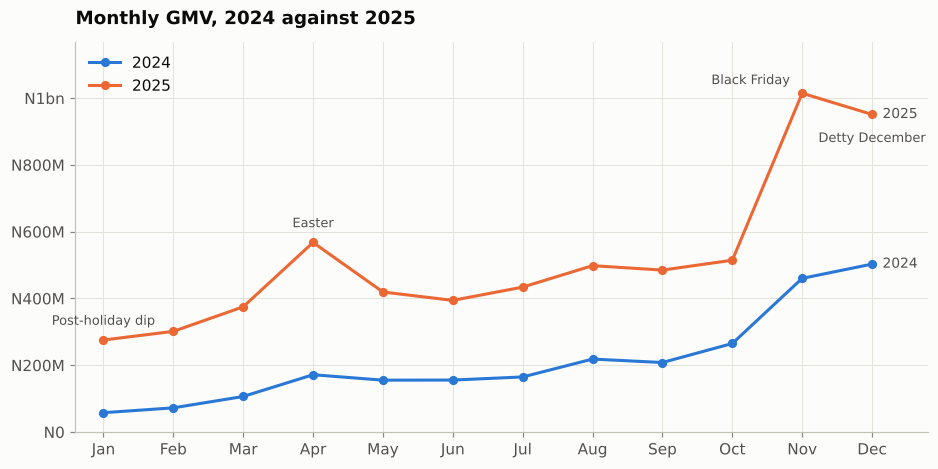

,gmv,orders
year,,
2024,"2,539,210,990.00","35,918.00"
2025,"6,230,790,745.00","78,263.00"
growth,1.45,1.18


In [7]:
monthly = live.groupby("month").agg(gmv=("order_total_ngn", "sum"), orders=("order_id", "size"))
monthly["year"] = monthly.index.year
monthly["m"] = monthly.index.month

fig, ax = plt.subplots(figsize=(10, 4.6))
for i, year in enumerate([2024, 2025]):
    s = monthly[monthly["year"] == year]
    ax.plot(s["m"], s["gmv"], marker="o", markersize=5, color=cp.SERIES[i], label=str(year))
    ax.text(12.15, s["gmv"].iloc[-1], str(year), va="center", color=cp.INK_2, fontsize=9)
s25 = monthly[monthly["year"] == 2025].set_index("m")["gmv"]
for m, label, offset, ha in [(1, "Post-holiday dip", (0, 10), "center"), (4, "Easter", (0, 10), "center"),
                             (11, "Black Friday", (-8, 6), "right"), (12, "Detty December", (0, -18), "center")]:
    ax.annotate(label, (m, s25[m]), textcoords="offset points", xytext=offset, ha=ha,
                fontsize=8.5, color=cp.INK_2)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlim(0.6, 12.8)
ax.set_ylim(0, s25.max() * 1.15)
cp.naira_axis(ax)
ax.set_title("Monthly GMV, 2024 against 2025")
ax.legend(loc="upper left")
cp.save(fig, "02_monthly_gmv_yoy")
plt.show()

yoy = monthly.groupby("year")[["gmv", "orders"]].sum()
yoy.loc["growth"] = yoy.loc[2025] / yoy.loc[2024] - 1
yoy

In [8]:
# Seasonal index: each month's orders against the average of the normal months (Mar, May to Sep).
idx = monthly.pivot(index="m", columns="year", values="orders")
base = idx.loc[[3, 5, 6, 7, 8, 9]].mean()
(idx / base).round(2).T

m,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2024,0.34,0.46,0.61,1.07,0.90,0.93,1.08,1.23,1.26,1.50,3.22,3.08
2025,0.67,0.73,0.88,1.42,0.99,0.93,1.01,1.09,1.10,1.20,2.56,2.22


GMV in 2025 is about 2.5 times 2024's, on 2.2 times the orders. Most of that is the customer base filling up: the dataset starts with zero customers in January 2024, so the 2024 line is a young business and the 2025 line is a full one. For that reason the 2025 seasonal index is the fair read. November runs at about 2.5 times a normal month and December at about 2.2. January drops to about 0.7 and April (Easter) lifts to about 1.4.

### A3. Order behaviour

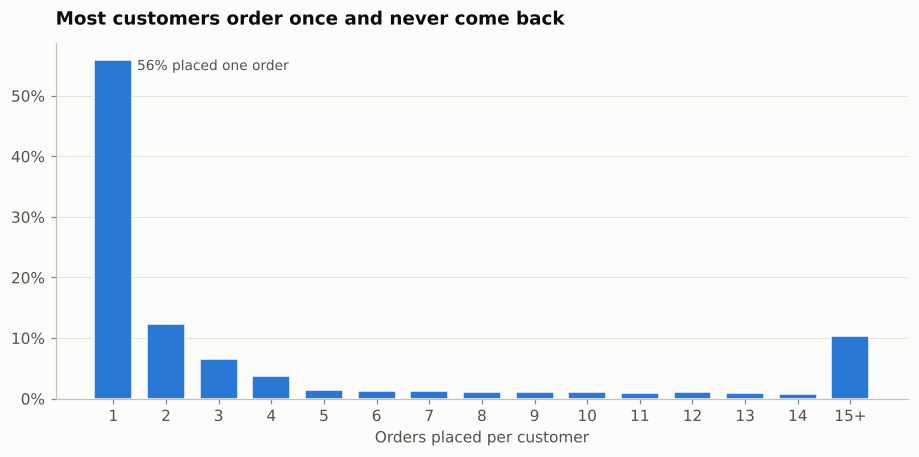

1 order          55.9%
2 to 4 orders    22.5%
5+ orders        21.6%
Name: proportion, dtype: str

In [9]:
n_orders = orders.groupby("customer_id").size().reindex(customers["customer_id"], fill_value=0)
dist = n_orders.clip(upper=15).value_counts().sort_index() / len(n_orders)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(dist.index, dist.values, color=cp.SERIES[0], width=0.72, edgecolor=cp.SURFACE)
ax.set_xticks(dist.index, [str(k) if k < 15 else "15+" for k in dist.index])
cp.pct_axis(ax)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Orders placed per customer")
ax.set_title("Most customers order once and never come back")
ax.text(1.45, dist.iloc[0] * 0.97, f"{dist.iloc[0]:.0%} placed one order", fontsize=9, color=cp.INK_2)
cp.save(fig, "02_orders_per_customer")
plt.show()

bands = pd.cut(n_orders, [0, 1, 4, np.inf], labels=["1 order", "2 to 4 orders", "5+ orders"])
bands.value_counts(normalize=True).sort_index().map("{:.1%}".format)

In [10]:
lines = items.groupby("order_id").agg(lines=("item_id", "size"), units=("quantity", "sum"))
print("Lines per order:", lines["lines"].value_counts(normalize=True).sort_index().round(3).to_dict())
print(f"Mean lines per order {lines['lines'].mean():.2f}, mean units {lines['units'].mean():.2f}")

status = orders["order_status"].value_counts(normalize=True)
print(f"\nCancelled {status['cancelled']:.1%}, returned {status['returned']:.1%}, delivered {status['delivered']:.1%}")

by_pay = orders.groupby("payment_method")["order_status"].value_counts(normalize=True).unstack()
by_cat = orders.assign(cat=orders["order_id"].map(lead_cat)).groupby("cat")["order_status"].value_counts(normalize=True).unstack()
pd.concat({"by payment method": by_pay[["cancelled", "returned"]],
           "by lead category": by_cat[["cancelled", "returned"]]}).style.format("{:.1%}")

Lines per order: {1: 0.301, 2: 0.301, 3: 0.219, 4: 0.179}
Mean lines per order 2.28, mean units 2.76

Cancelled 5.7%, returned 5.0%, delivered 89.3%


Pay on delivery has more than twice the cancellation rate of other methods: customers refuse the parcel at the door. Fashion has the highest return rate, which fits a category where fit and look decide whether the item stays.

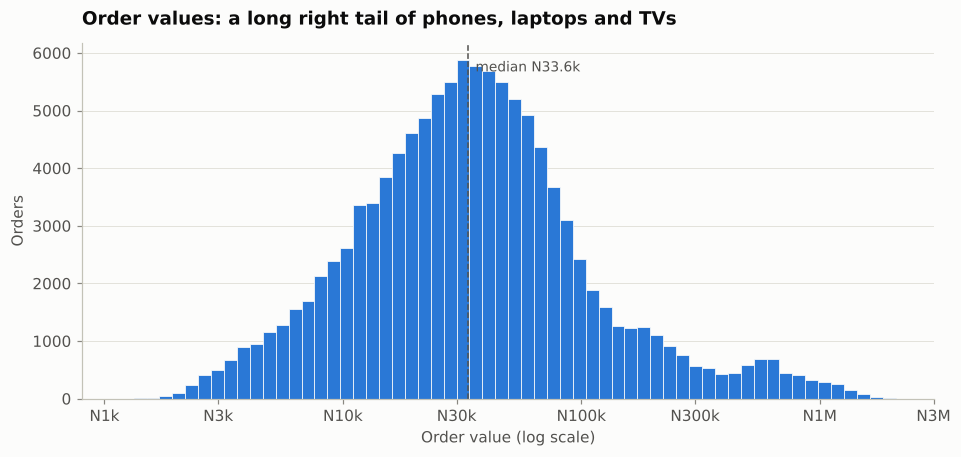

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(np.log10(live["order_total_ngn"]), bins=60, color=cp.SERIES[0], edgecolor=cp.SURFACE, linewidth=0.5)
ticks = [1e3, 3e3, 1e4, 3e4, 1e5, 3e5, 1e6, 3e6]
ax.set_xticks(np.log10(ticks), [cp.naira(v, 0) for v in ticks])
ax.grid(axis="x", visible=False)
ax.axvline(np.log10(live["order_total_ngn"].median()), color=cp.INK_2, linewidth=1, linestyle="--")
ax.text(np.log10(live["order_total_ngn"].median()) + 0.03, ax.get_ylim()[1] * 0.92,
        f"median {cp.naira(live['order_total_ngn'].median())}", fontsize=9, color=cp.INK_2)
ax.set_xlabel("Order value (log scale)")
ax.set_ylabel("Orders")
ax.set_title("Order values: a long right tail of phones, laptops and TVs")
plt.show()

### A4. Products and categories

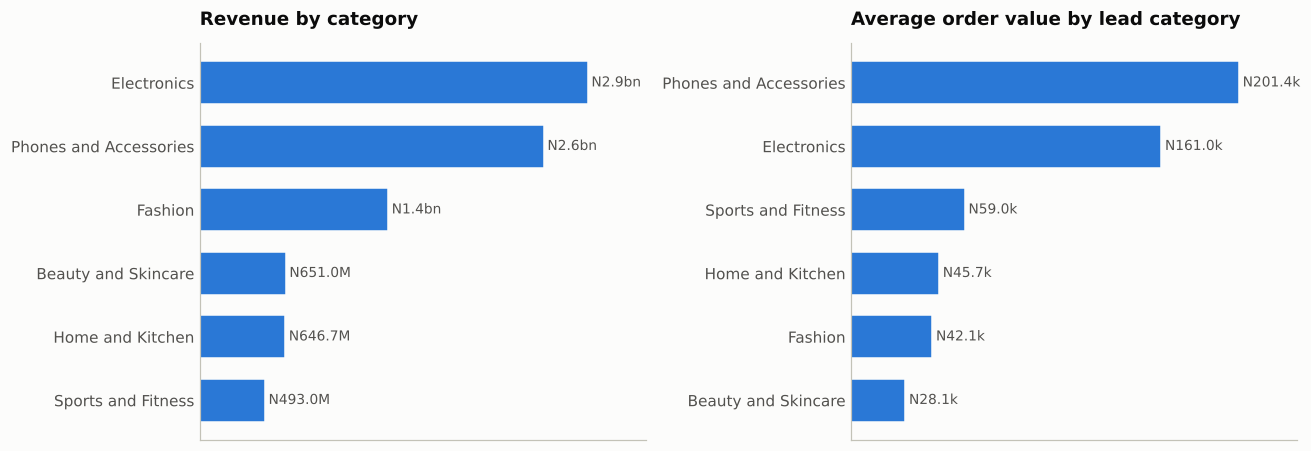

,revenue,units,avg_unit_price,revenue_share,aov_as_lead
category,,,,,
Electronics,N2.9bn,"43,020",N75.9k,33.6%,N161.0k
Phones and Accessories,N2.6bn,"34,606",N84.8k,29.7%,N201.4k
Fashion,N1.4bn,"100,254",N15.0k,16.3%,N42.1k
Beauty and Skincare,N651.0M,"79,556",N8.6k,7.4%,N28.1k
Home and Kitchen,N646.7M,"37,153",N18.4k,7.4%,N45.7k
Sports and Fitness,N493.0M,"20,236",N25.9k,5.6%,N59.0k


In [12]:
it = items.merge(products, on="product_id").merge(orders[["order_id", "order_status"]], on="order_id")
it = it[it["order_status"] != "cancelled"]
it["net_ngn"] = it["quantity"] * it["unit_price_ngn"] * (1 - it["discount_pct"] / 100)

cat = it.groupby("category").agg(revenue=("net_ngn", "sum"), units=("quantity", "sum"),
                                 avg_unit_price=("unit_price_ngn", "mean")).sort_values("revenue", ascending=False)
cat["revenue_share"] = cat["revenue"] / cat["revenue"].sum()
cat["aov_as_lead"] = aov.groupby("cat")["order_total_ngn"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cp.hbar(axes[0], cat.index, cat["revenue"], fmt=cp.naira)
axes[0].set_title("Revenue by category")
axes[0].set_xticks([])
a = cat.sort_values("aov_as_lead", ascending=False)
cp.hbar(axes[1], a.index, a["aov_as_lead"], fmt=cp.naira)
axes[1].set_title("Average order value by lead category")
axes[1].set_xticks([])
fig.tight_layout()
cp.save(fig, "02_category_revenue_aov")
plt.show()

cat.style.format({"revenue": cp.naira, "units": "{:,.0f}", "avg_unit_price": cp.naira,
                  "revenue_share": "{:.1%}", "aov_as_lead": cp.naira})

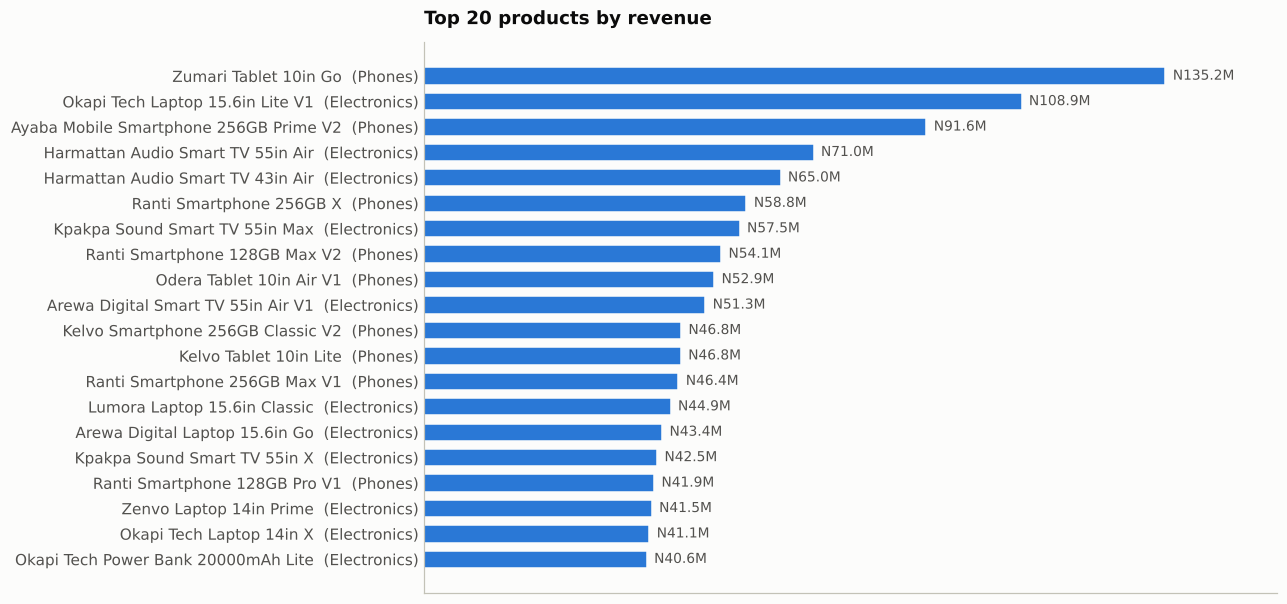

category
Electronics               11
Phones and Accessories     9


In [13]:
top = it.groupby(["product_name", "category"])["net_ngn"].sum().sort_values(ascending=False).head(20).reset_index()

fig, ax = plt.subplots(figsize=(10, 6.5))
cp.hbar(ax, top["product_name"] + "  (" + top["category"].str.split().str[0] + ")", top["net_ngn"], fmt=cp.naira)
ax.set_xticks([])
ax.set_title("Top 20 products by revenue")
cp.save(fig, "02_top20_products")
plt.show()

print(top["category"].value_counts().to_string())

Electronics brings in the most revenue (about a third), with Phones and Accessories close behind. Orders led by a phone or tablet carry the highest average value of any category. Fashion and Beauty sell the most units but at low prices, so their revenue share sits far below their share of units. The top 20 products are tablets, smartphones, laptops and TVs, plus one power bank that earns its place on volume.

### A5. Geography

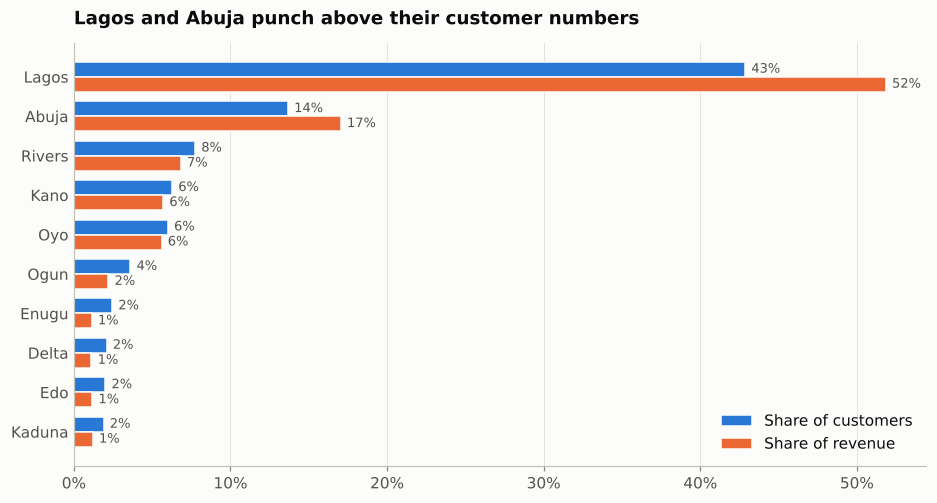

,customers,revenue,customer_share,revenue_share,revenue_per_customer,avg_delivery_days
state,,,,,,
Lagos,"10,715",N4.5bn,42.9%,51.8%,N424.3k,4.0
Abuja,"3,417",N1.5bn,13.7%,17.0%,N437.4k,4.5
Rivers,"1,934",N598.3M,7.7%,6.8%,N309.3k,6.5
Kano,"1,567",N499.5M,6.3%,5.7%,N318.8k,6.5
Oyo,"1,499",N490.7M,6.0%,5.6%,N327.4k,6.5
Ogun,900,N192.9M,3.6%,2.2%,N214.3k,11.5
Enugu,610,N99.8M,2.4%,1.1%,N163.6k,11.6
Delta,522,N98.2M,2.1%,1.1%,N188.1k,11.5
Edo,501,N102.7M,2.0%,1.2%,N204.9k,11.5


In [14]:
geo = (customers.groupby("state").size().rename("customers").to_frame()
       .join(live.merge(customers[["customer_id", "state"]], on="customer_id")
             .groupby("state")["order_total_ngn"].sum().rename("revenue")))
geo["customer_share"] = geo["customers"] / geo["customers"].sum()
geo["revenue_share"] = geo["revenue"] / geo["revenue"].sum()
geo["revenue_per_customer"] = geo["revenue"] / geo["customers"]
geo["avg_delivery_days"] = orders.groupby("delivery_state")["delivery_days"].mean()
geo = geo.sort_values("customers", ascending=False)
top10 = geo.head(10)

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(top10))[::-1]
h = 0.38
ax.barh(y + h / 2, top10["customer_share"], height=h, color=cp.SERIES[0], label="Share of customers", edgecolor=cp.SURFACE)
ax.barh(y - h / 2, top10["revenue_share"], height=h, color=cp.SERIES[1], label="Share of revenue", edgecolor=cp.SURFACE)
for yi, c, r in zip(y, top10["customer_share"], top10["revenue_share"]):
    ax.text(c + 0.004, yi + h / 2, f"{c:.0%}", va="center", fontsize=8.5, color=cp.INK_2)
    ax.text(r + 0.004, yi - h / 2, f"{r:.0%}", va="center", fontsize=8.5, color=cp.INK_2)
ax.set_yticks(y, top10.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
cp.pct_axis(ax, axis="x")
ax.legend(loc="lower right")
ax.set_title("Lagos and Abuja punch above their customer numbers")
cp.save(fig, "02_state_share")
plt.show()

geo.head(10).style.format({"customers": "{:,}", "revenue": cp.naira, "customer_share": "{:.1%}",
                           "revenue_share": "{:.1%}", "revenue_per_customer": cp.naira,
                           "avg_delivery_days": "{:.1f}"})

In [15]:
tier = np.where(geo.index.isin(cp.TOP5_STATES), "Top 5 states", "Rest of Nigeria")
print(geo.groupby(tier).agg(customers=("customers", "sum"), revenue=("revenue", "sum"),
                            avg_delivery_days=("avg_delivery_days", "mean")).to_string())

                 customers          revenue  avg_delivery_days
Rest of Nigeria       5868 1,140,161,072.50              11.50
Top 5 states         19132 7,629,840,662.50               5.62


Lagos has about 43% of customers and about 51% of revenue; Abuja has 14% and 17%. Their customers spend more per head than anyone else. Outside the top five states, parcels take 8 to 14 days against 2 to 5 in Lagos, and that slower service is the first suspect for weaker retention there (tested in notebook 03).

### A6. Payment methods

The plan called for a pie here. A bar chart replaces it: five slices of similar size are hard to compare by angle, and bars put the retention preview on the same footing.

Ninety-day retention means the customer placed a second order within 90 days of their first. Only customers whose first order was at least 90 days before the snapshot are counted, so everyone had the full window.

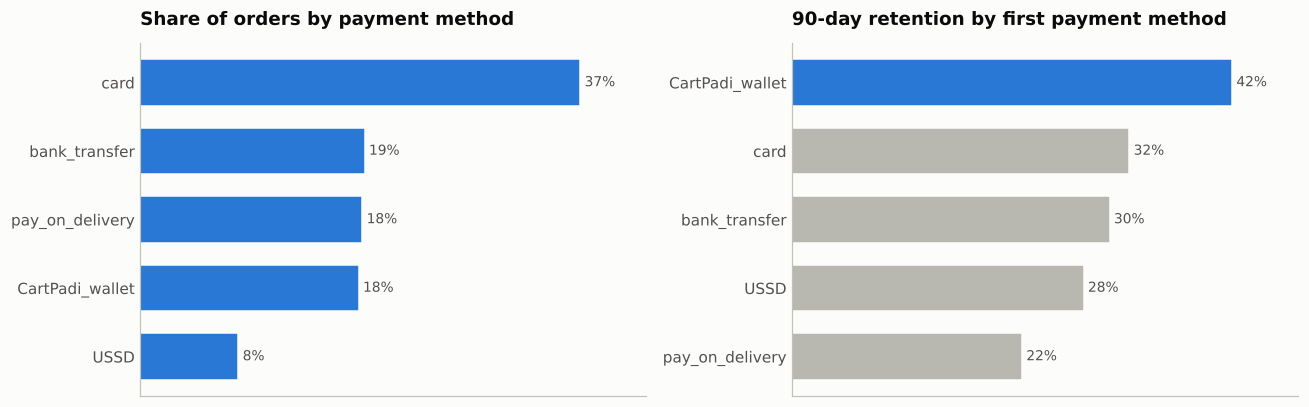

,share_of_orders,ret90_by_first_payment
payment_method,,
CartPadi_wallet,18.2%,42.2%
card,36.6%,32.3%
bank_transfer,18.7%,30.4%
USSD,8.2%,27.9%
pay_on_delivery,18.5%,22.0%


In [16]:
o = orders.sort_values("order_date").copy()
o["seq"] = o.groupby("customer_id").cumcount()
first = o[o["seq"] == 0].set_index("customer_id")
second = o[o["seq"] == 1].set_index("customer_id")["order_date"]
first["days_to_second"] = (second - first["order_date"]).dt.days
mature = first[first["order_date"] < cp.SNAPSHOT_END - pd.Timedelta(days=90)].copy()
mature["ret90"] = mature["days_to_second"].le(90)
mature = mature.join(customers.set_index("customer_id")[["acquisition_channel", "state", "signup_date"]])

pay = pd.DataFrame({
    "share_of_orders": orders["payment_method"].value_counts(normalize=True),
    "ret90_by_first_payment": mature.groupby("payment_method")["ret90"].mean(),
}).sort_values("ret90_by_first_payment", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
s = pay.sort_values("share_of_orders", ascending=False)
cp.hbar(axes[0], s.index, s["share_of_orders"], fmt=lambda v: f"{v:.0%}")
axes[0].set_xticks([])
axes[0].set_title("Share of orders by payment method")
cp.hbar(axes[1], pay.index, pay["ret90_by_first_payment"], fmt=lambda v: f"{v:.0%}", highlight="CartPadi_wallet")
axes[1].set_xticks([])
axes[1].set_title("90-day retention by first payment method")
fig.tight_layout()
cp.save(fig, "02_payment_methods")
plt.show()
pay.style.format("{:.1%}")

Card is the most used method. The retention gap is the real story: customers who first paid from a CartPadi wallet come back at roughly twice the rate of pay-on-delivery customers. Money already sitting in the wallet is a reason to return.

### A7. Customer acquisition

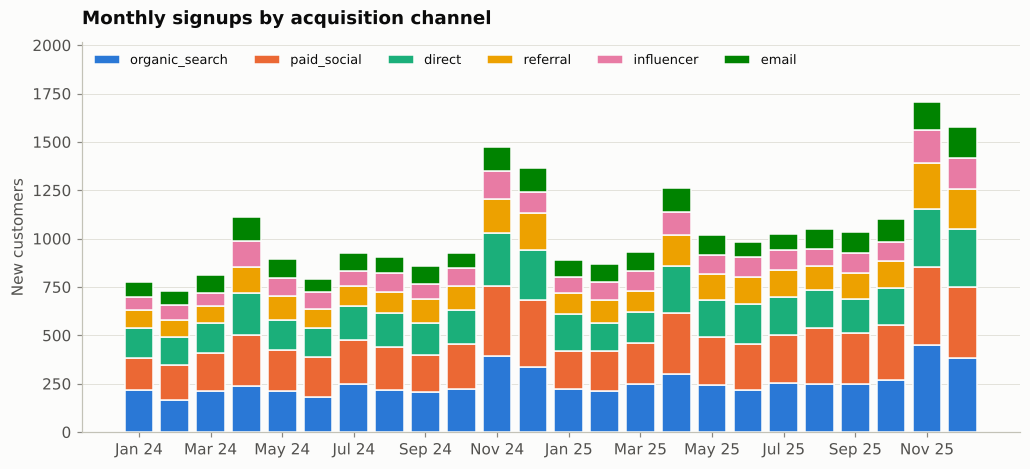

,share,ret90
acquisition_channel,,
organic_search,24.6%,31.6%
paid_social,24.3%,19.0%
direct,18.8%,35.4%
referral,12.8%,41.9%
influencer,9.8%,23.3%
email,9.7%,39.0%


In [17]:
signups = customers.assign(month=customers["signup_date"].dt.to_period("M"))
by_ch = signups.groupby(["month", "acquisition_channel"]).size().unstack(fill_value=0)
order = by_ch.sum().sort_values(ascending=False).index
by_ch = by_ch[order]

fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(by_ch))
bottom = np.zeros(len(by_ch))
for i, ch in enumerate(order):
    ax.bar(x, by_ch[ch], bottom=bottom, color=cp.SERIES[i], width=0.8, label=ch, edgecolor=cp.SURFACE, linewidth=1)
    bottom += by_ch[ch].to_numpy()
ax.set_xticks(x[::2], [p.strftime("%b %y") for p in by_ch.index[::2]])
ax.grid(axis="x", visible=False)
ax.set_ylabel("New customers")
ax.set_title("Monthly signups by acquisition channel")
ax.legend(ncols=6, loc="upper left", fontsize=8.5)
ax.set_ylim(0, bottom.max() * 1.18)
cp.save(fig, "02_signups_by_channel")
plt.show()

mix = customers["acquisition_channel"].value_counts(normalize=True)
mix.to_frame("share").assign(ret90=mature.groupby("acquisition_channel")["ret90"].mean()).style.format("{:.1%}")

Signups follow the same calendar as orders: they surge in November and December. Organic search and paid social bring in the most customers. Paid social also has the worst 90-day retention of any channel, while referral has the best, at more than twice paid social's rate. Notebook 03 follows these channels month by month.

## Part B: RFM segmentation

### B1. Recency, frequency, monetary

All three measures use orders that were not cancelled, as of the snapshot (31 December 2025).

1. Recency (R): days from the last order to the snapshot.
2. Frequency (F): number of orders.
3. Monetary (M): total spend in naira on delivered orders. Returned orders are refunded, so they add nothing.

Customers whose only orders were cancelled never completed a purchase. They sit outside RFM in their own group.

In [18]:
rfm = live.groupby("customer_id").agg(
    last_order=("order_date", "max"),
    frequency=("order_id", "size"),
)
rfm["monetary"] = live[live["order_status"] == "delivered"].groupby("customer_id")["order_total_ngn"].sum()
rfm["monetary"] = rfm["monetary"].fillna(0)
rfm["recency"] = (cp.SNAPSHOT_END - rfm["last_order"]).dt.days
never = customers.loc[~customers["customer_id"].isin(rfm.index), "customer_id"]
print(f"Customers with an RFM profile: {len(rfm):,}")
print(f"Customers with only cancelled orders: {len(never):,}")
rfm[["recency", "frequency", "monetary"]].describe(percentiles=[0.2, 0.4, 0.5, 0.6, 0.8]).T

Customers with an RFM profile: 23,837
Customers with only cancelled orders: 1,163


,count,mean,std,min,20%,40%,50%,60%,80%,max
recency,"23,837.00",236.79,210.34,0.00,23.00,111.00,191.00,270.00,432.00,730.00
frequency,"23,837.00",4.79,8.00,1.00,1.00,1.00,1.00,2.00,6.00,78.00
monetary,"23,837.00","350,807.68","710,938.96",0.00,"19,450.00","46,858.00","69,200.00","111,259.00","484,223.00","12,202,185.00"


### B2. Scores from 1 to 5

Recency and monetary use quintiles: each score holds a fifth of customers. Recency is reversed, so 5 is the most recent.

Frequency can't use quintiles. More than half of customers have exactly one order, so the bottom three quintiles would all be "1 order" split at random. Frequency gets fixed bands instead: 1, 2, 3 to 4, 5 to 9, and 10 or more orders.

In [19]:
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.cut(rfm["frequency"], [0, 1, 2, 4, 9, np.inf], labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_score"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

bounds = pd.DataFrame({
    "recency_days": rfm.groupby("R")["recency"].agg(["min", "max"]).astype(int).astype(str).agg(" to ".join, axis=1),
    "orders": rfm.groupby("F")["frequency"].agg(["min", "max"]).astype(int).astype(str).agg(" to ".join, axis=1),
    "spend": rfm.groupby("M")["monetary"].agg(["min", "max"]).apply(lambda r: f"{cp.naira(r['min'])} to {cp.naira(r['max'])}", axis=1),
    "customers_R": rfm["R"].value_counts(), "customers_F": rfm["F"].value_counts(),
})
bounds.index.name = "score"
bounds

,recency_days,orders,spend,customers_R,customers_F
score,,,,,
1,432 to 730,1 to 1,N0 to N19.4k,4768,13138
2,270 to 432,2 to 2,N19.4k to N46.9k,4767,3039
3,111 to 270,3 to 4,N46.9k to N111.2k,4767,2353
4,23 to 111,5 to 9,N111.3k to N484.2k,4767,1624
5,0 to 23,10 to 78,N484.2k to N12.2M,4768,3683


### B3. Segment rules

The plan's segment table overlaps: a customer with R=5 and F=5 fits Champions, Loyal Customers and Potential Loyalists at once. The rules below are applied in order and the first match wins, so every customer lands in exactly one segment.

| Order | Segment | Rule |
|---|---|---|
| 1 | Champions | R = 5, F 4 to 5, M 4 to 5 |
| 2 | Loyal Customers | R 4 to 5, F 3 to 5 |
| 3 | Potential Loyalists | R 4 to 5, F = 2 |
| 4 | Recent Customers | R 4 to 5, F = 1 |
| 5 | At Risk | R 2 to 3, F 3 to 5 |
| 6 | About to Sleep | R 2 to 3, F 1 to 2 |
| 7 | Lost | R = 1, F = 1 |
| 8 | Hibernating | R = 1, F 2 to 5 |

Two departures from the plan, both to remove overlap. Loyal Customers starts at R=4, so a frequent buyer who has gone quiet (R=3) counts as At Risk, which is the more useful flag. Hibernating covers lapsed customers who bought more than once, which separates them from one-time buyers who are simply Lost.

In [20]:
def segment(r, f, m):
    if r == 5 and f >= 4 and m >= 4:
        return "Champions"
    if r >= 4 and f >= 3:
        return "Loyal Customers"
    if r >= 4 and f == 2:
        return "Potential Loyalists"
    if r >= 4:
        return "Recent Customers"
    if r >= 2 and f >= 3:
        return "At Risk"
    if r >= 2:
        return "About to Sleep"
    if f == 1:
        return "Lost"
    return "Hibernating"


SEGMENTS = ["Champions", "Loyal Customers", "Potential Loyalists", "Recent Customers",
            "At Risk", "About to Sleep", "Hibernating", "Lost"]
rfm["segment"] = [segment(r, f, m) for r, f, m in zip(rfm["R"], rfm["F"], rfm["M"])]
rfm["segment"] = pd.Categorical(rfm["segment"], categories=SEGMENTS, ordered=True)

seg = rfm.groupby("segment", observed=False).agg(
    customers=("R", "size"), avg_recency=("recency", "mean"), avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"), revenue=("monetary", "sum"))
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()
seg.style.format({"customers": "{:,}", "avg_recency": "{:,.0f}", "avg_frequency": "{:.1f}",
                  "avg_monetary": cp.naira, "revenue": cp.naira, "customer_share": "{:.1%}",
                  "revenue_share": "{:.1%}"})

,customers,avg_recency,avg_frequency,avg_monetary,revenue,customer_share,revenue_share
segment,,,,,,,
Champions,"2,847",7,17.7,N1.4M,N3.8bn,11.9%,46.0%
Loyal Customers,"1,864",42,10.0,N718.7k,N1.3bn,7.8%,16.0%
Potential Loyalists,997,39,2.0,N170.8k,N170.3M,4.2%,2.0%
Recent Customers,"3,827",46,1.0,N81.8k,N313.1M,16.1%,3.7%
At Risk,"2,318",275,9.6,N627.7k,N1.5bn,9.7%,17.4%
About to Sleep,"7,216",278,1.2,N91.9k,N663.5M,30.3%,7.9%
Hibernating,"1,312",542,3.7,N242.2k,N317.8M,5.5%,3.8%
Lost,"3,456",571,1.0,N74.4k,N257.3M,14.5%,3.1%


### B4. Segment size against revenue

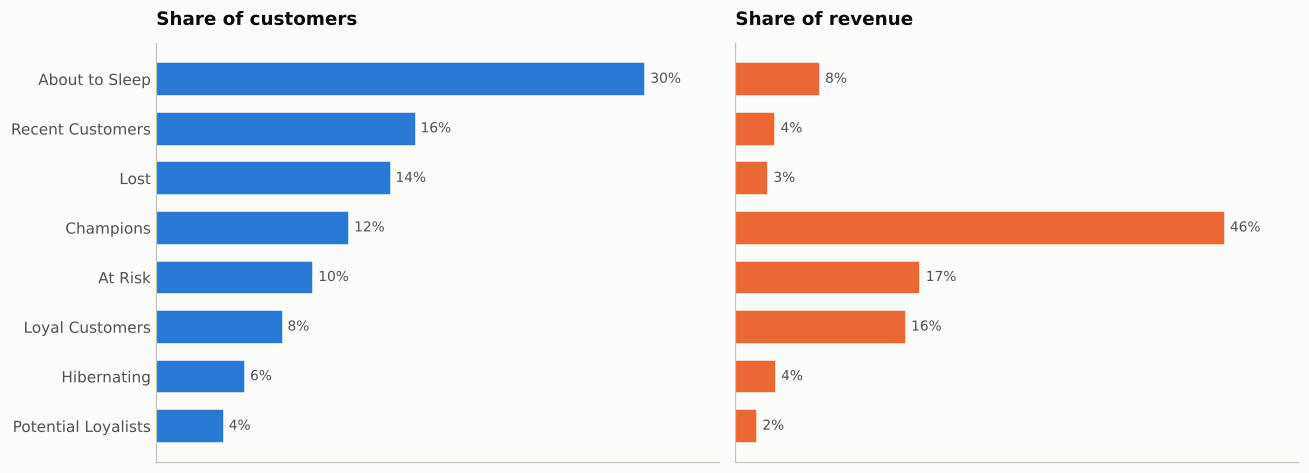

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
s = seg.sort_values("customers", ascending=False)
cp.hbar(axes[0], s.index, s["customer_share"], fmt=lambda v: f"{v:.0%}")
axes[0].set_title("Share of customers")
axes[0].set_xticks([])
y = np.arange(len(s))[::-1]
axes[1].barh(y, s["revenue_share"], color=cp.SERIES[1], height=0.68, edgecolor=cp.SURFACE)
for yi, v in zip(y, s["revenue_share"]):
    axes[1].text(v + 0.005, yi, f"{v:.0%}", va="center", fontsize=9, color=cp.INK_2)
axes[1].set_xlim(0, s["revenue_share"].max() * 1.15)
axes[1].grid(axis="y", visible=False)
axes[1].set_xticks([])
axes[1].tick_params(axis="y", length=0)
axes[1].set_title("Share of revenue")
fig.tight_layout()
cp.save(fig, "02_segment_size_revenue")
plt.show()

### B5. Segment profiles

Each column is shaded on its own scale, so the colour compares segments within one measure. The numbers in the cells are the real averages.

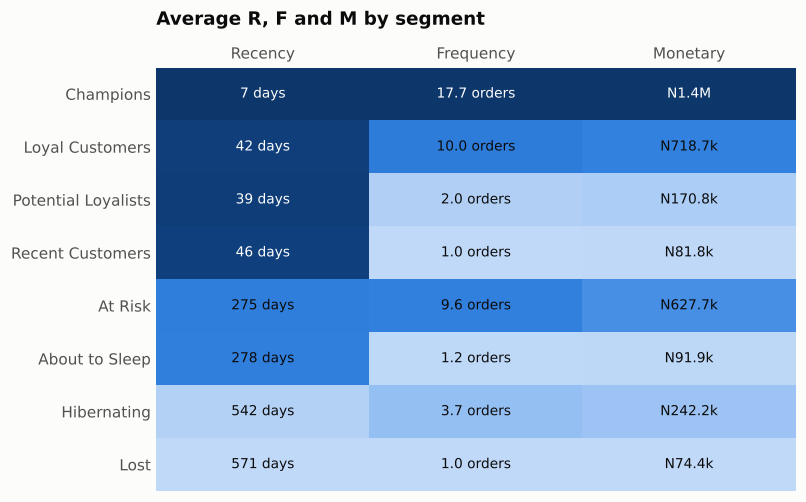

In [22]:
prof = seg[["avg_recency", "avg_frequency", "avg_monetary"]]
shade = (prof - prof.min()) / (prof.max() - prof.min())
shade["avg_recency"] = 1 - shade["avg_recency"]  # recent = dark

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.imshow(shade.to_numpy(), cmap=cp.SEQ_CMAP, aspect="auto", vmin=-0.05, vmax=1)
labels = {"avg_recency": lambda v: f"{v:,.0f} days", "avg_frequency": lambda v: f"{v:.1f} orders",
          "avg_monetary": cp.naira}
for i in range(len(prof)):
    for j, col in enumerate(prof.columns):
        ax.text(j, i, labels[col](prof.iloc[i, j]), ha="center", va="center", fontsize=9,
                color="white" if shade.iloc[i, j] > 0.55 else cp.INK)
ax.set_xticks(range(3), ["Recency", "Frequency", "Monetary"])
ax.set_yticks(range(len(prof)), prof.index)
ax.tick_params(length=0)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.xaxis.tick_top()
ax.set_title("Average R, F and M by segment", pad=28)
cp.save(fig, "02_segment_heatmap")
plt.show()

### B6. Recency against frequency

Every customer is a grey dot (frequency is jittered so the dots don't stack). The labelled bubbles are each segment's average position, sized by average spend. With eight segments, colouring all 24,000 dots would leave colours nobody can tell apart.

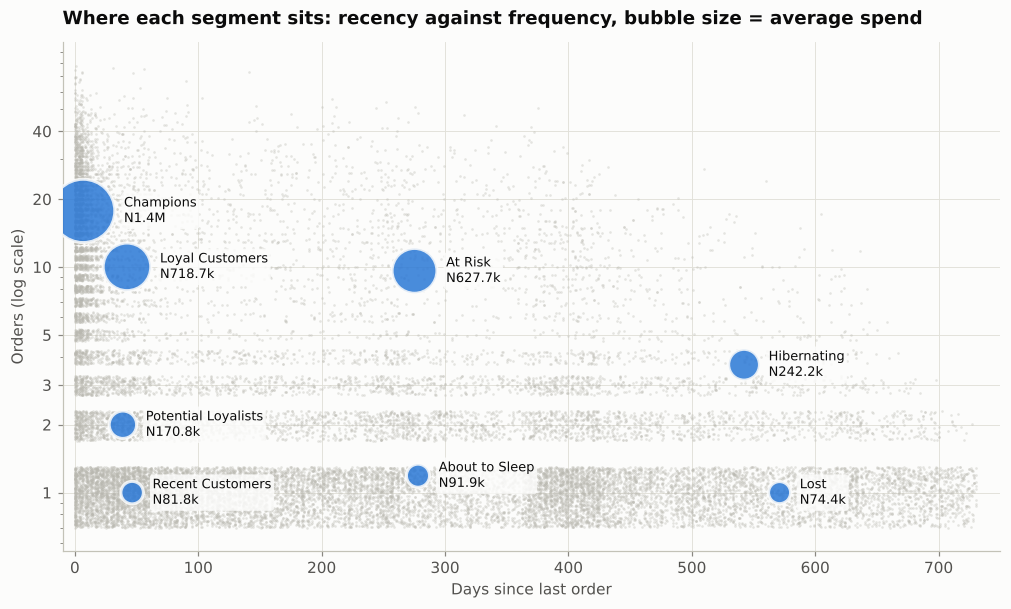

In [23]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(rfm["recency"], rfm["frequency"] + rng.uniform(-0.3, 0.3, len(rfm)), s=3, color=cp.NEUTRAL,
           alpha=0.35, linewidths=0)
cent = rfm.groupby("segment", observed=True).agg(r=("recency", "mean"), f=("frequency", "mean"),
                                                 m=("monetary", "mean"))
size = 120 + 1600 * cent["m"] / cent["m"].max()
ax.scatter(cent["r"], cent["f"], s=size, color=cp.SERIES[0], alpha=0.85, edgecolor=cp.SURFACE, linewidth=2, zorder=3)
for name, row in cent.iterrows():
    ax.annotate(f"{name}\n{cp.naira(row['m'])}", (row["r"], row["f"]), textcoords="offset points",
                xytext=(np.sqrt(size[name]) / 2 + 6, 0), ha="left", va="center", fontsize=8.5,
                color=cp.INK, zorder=4,
                bbox=dict(boxstyle="round,pad=0.2", facecolor=cp.SURFACE, edgecolor="none", alpha=0.85))
ax.set_yscale("log")
ax.set_yticks([1, 2, 3, 5, 10, 20, 40], ["1", "2", "3", "5", "10", "20", "40"])
ax.set_xlabel("Days since last order")
ax.set_ylabel("Orders (log scale)")
ax.set_xlim(-10, rfm["recency"].max() + 20)
ax.set_title("Where each segment sits: recency against frequency, bubble size = average spend")
cp.save(fig, "02_segment_scatter")
plt.show()

### B7. Export

In [24]:
out = rfm.reset_index()[["customer_id", "recency", "frequency", "monetary", "R", "F", "M", "RFM_score", "segment"]]
out["segment"] = out["segment"].astype(str)
none = pd.DataFrame({"customer_id": never, "segment": "No completed order"})
out = pd.concat([out, none], ignore_index=True)
out = out.rename(columns={"recency": "recency_days", "frequency": "frequency_orders", "monetary": "monetary_ngn"})

cp.PROCESSED.mkdir(parents=True, exist_ok=True)
out.to_csv(cp.PROCESSED / "rfm_segments.csv", index=False)
print(f"Wrote {len(out):,} rows to data/processed/rfm_segments.csv")
out["segment"].value_counts()

Wrote 25,000 rows to data/processed/rfm_segments.csv


segment
About to Sleep         7216
Recent Customers       3827
Lost                   3456
Champions              2847
At Risk                2318
Loyal Customers        1864
Hibernating            1312
No completed order     1163
Potential Loyalists     997
Name: count, dtype: int64

## Findings

1. More than half of customers (55.9%) order once and never come back. The 21.6% who place five or more orders carry the business.
2. Champions are 12% of customers and 46% of revenue. Add Loyal Customers and one customer in five brings in 62% of revenue.
3. At Risk is the most urgent list: 2,318 customers who averaged 9.6 orders and N627.7k each, then went quiet for about nine months. They hold 17% of revenue to date.
4. About to Sleep is the largest segment at 30% of customers: one- and two-time buyers last seen three to nine months ago. Cheap to reach, low value each, large in total.
5. Where a customer comes from and how they pay already predicts whether they return. Paid social brings in a quarter of customers but only 19% buy again within 90 days, against 42% for referral. Customers who first paid from a CartPadi wallet return at 42%, against 22% for pay on delivery.
6. November and December run at about 2.6 and 2.2 times a normal month. The customers acquired in that rush are tested for loyalty in notebook 03.